[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/09_priors.py)

# Priors in Gaussian Mixture Models

Priors turn the maximum-likelihood M-step of EM into a **maximum a posteriori (MAP)** update: each parameter estimate is pulled toward a prior guess by an amount that depends on how much data supports the component. This regularizes the model, prevents degenerate (collapsed) components, and lets you encode domain knowledge. This notebook builds up the three priors `tgmm` supports, deriving the distributions involved and showing how each one changes a fit.

**What you'll learn**

- how a Dirichlet prior on the weights (`weight_concentration_prior`) shapes the mixing proportions, and the MAP weight update it produces
- how a Gaussian prior on the means (`mean_prior`, `mean_precision_prior`) acts as pseudo-observations
- why an inverse-Wishart (or inverse-Gamma) prior is the natural choice for covariances, and how `covariance_prior` and `degrees_of_freedom_prior` change a fit
- how the conjugate Normal-Inverse-Wishart (NIW) prior couples means and covariances, and the exact posterior update tgmm uses

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb), [02 -- EM Algorithm](02_em_algorithm.ipynb), [03 -- Visualization](03_visualise.ipynb) (for `plot_gmm`).
See also the [Gaussian Mixture Model user guide](../user-guide/gaussian-mixture.md).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import scipy.special
from scipy.stats import wishart, invgamma
from scipy.ndimage import gaussian_filter


from tgmm import GaussianMixture, GMMInitializer, dynamic_figsize, plot_gmm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; keep embedded figure outputs small

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Using device: {device}')

Using device: cpu


## Synthetic Data Generation

The synthetic dataset is generated by combining four Gaussian components:

- **Component 1:** Centered at `[0, 2]` with spherical covariance.
- **Component 2:** Centered at `[2, -2]` with spherical covariance (fewer points).
- **Component 3:** Centered at `[0, 0]` with diagonal covariance.
- **Component 4:** Centered at `[2, 2]` with full covariance.

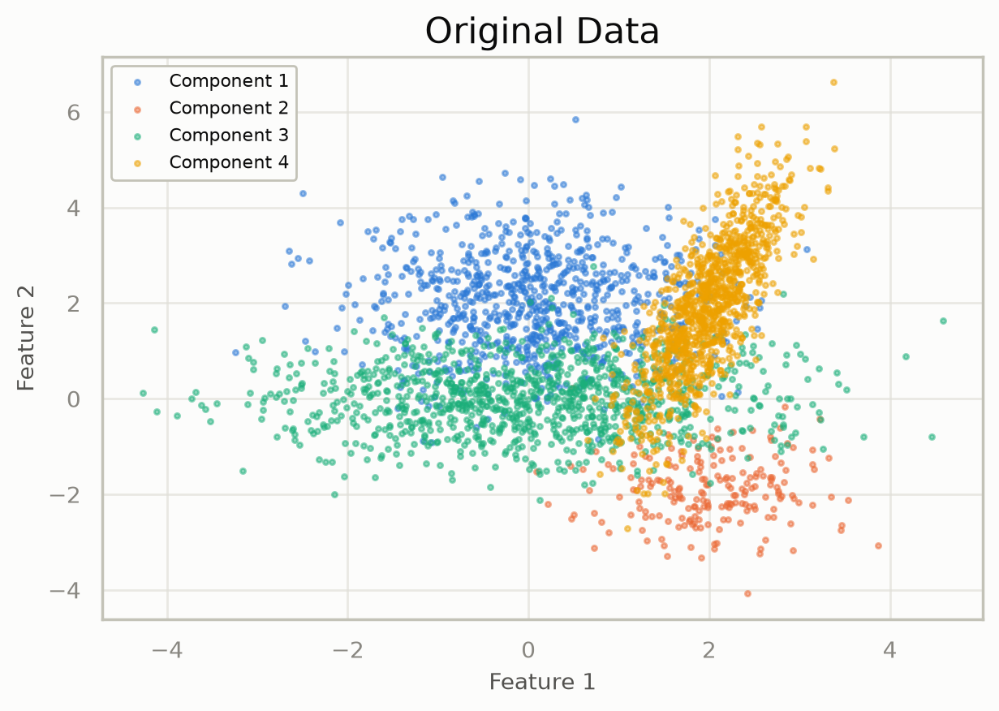

In [ ]:
_n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]), np.array([2, -2]), np.array([0, 0]), np.array([2, 2])]
covs = [1.0 * np.eye(2), 0.5 * np.eye(2), np.array([[2, 0], [0, 0.5]]), np.array([[0.2, 0.5], [0.5, 2]])]
components = []
for n, center, _cov in zip(_n_samples, centers, covs):
    _samples = np.random.randn(n, 2) @ np.linalg.cholesky(_cov).T + center
    components.append(_samples)  # spherical covariance
X = np.vstack(components)  # spherical covariance, fewer points
labels = np.concatenate([i * np.ones(n) for i, n in enumerate(_n_samples)])  # diagonal covariance
legend_labels = [f'Component {i + 1}' for i in range(len(_n_samples))]  # full covariance
X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
n_features = X.shape[1]
n_components = len(_n_samples)
plot_gmm(X=X, true_labels=labels, title='Original Data', legend_labels=legend_labels)
plt.gcf()

## Dirichlet Distribution: Definition and Derivation from the Beta Distribution

The Dirichlet distribution is a multivariate generalization of the Beta distribution. For a vector
$$
\mathbf{x} = (x_1, x_2, \dots, x_K)
$$
that lies in the $(K-1)$-simplex, i.e.,
$$
\sum_{i=1}^K x_i = 1 \quad \text{and} \quad x_i \ge 0 \quad \text{for all } i,
$$
the Dirichlet distribution with parameter vector
$$
\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_K) \quad \text{with} \quad \alpha_i > 0,
$$
is defined by its probability density function
$$
f(x_1, \dots, x_K; \boldsymbol{\alpha}) = \frac{1}{B(\boldsymbol{\alpha})} \prod_{i=1}^K x_i^{\alpha_i - 1},
$$
where the normalizing constant $B(\boldsymbol{\alpha})$ is the multivariate Beta function:
$$
B(\boldsymbol{\alpha}) = \frac{\prod_{i=1}^K \Gamma(\alpha_i)}{\Gamma\left(\sum_{i=1}^K \alpha_i\right)}.
$$

### Derivation from the Beta Distribution

For the special case $K=2$, let
$$
x_1 = x \quad \text{and} \quad x_2 = 1 - x.
$$
Then the Dirichlet density becomes
$$
f(x; \alpha_1, \alpha_2) = \frac{1}{B(\alpha_1, \alpha_2)} x^{\alpha_1 - 1} (1 - x)^{\alpha_2 - 1},
$$
with
$$
B(\alpha_1, \alpha_2) = \frac{\Gamma(\alpha_1)\Gamma(\alpha_2)}{\Gamma(\alpha_1 + \alpha_2)}.
$$
This is exactly the density of the Beta distribution, denoted as
$$
\operatorname{Beta}(\alpha_1,\alpha_2).
$$

### Symmetric Dirichlet Distribution
In its most general form, the Dirichlet distribution has a parameter vector $\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_K)$, with each $\alpha_i$ playing a role similar to that in the Beta distribution. However, in many practical applications—especially when there is no prior reason to favor one category over another—a **symmetric Dirichlet distribution** is used. In the symmetric case, all parameters are set equal, i.e.,
$$
\alpha_1 = \alpha_2 = \cdots = \alpha_K = \alpha.
$$
This reduces the number of free parameters from $K$ to one, and the density function simplifies to
$$
f(x_1,\dots,x_K; \alpha) = \frac{\Gamma(K\alpha)}{[\Gamma(\alpha)]^K} \prod_{i=1}^K x_i^{\alpha - 1}.
$$
Thus, while the general Dirichlet has $K$ parameters, the symmetric case is completely described by a single concentration parameter $\alpha$.

### How Does $\alpha$ Affect the Dirichlet Distribution?

- **Small $\alpha$ ($\alpha \ll 1$):**
  When $\alpha$ is much less than 1, the distribution is *sparse*, favoring configurations where one or a few weights are near 1 while the others are close to 0. This tends to lead to “hard” clustering where only a few components dominate.

- **Uniform Case ($\alpha = 1$):**
  For $\alpha = 1$, the Dirichlet distribution is uniform over the simplex, meaning that all weight configurations are equally likely a priori.

- **Large $\alpha$ ($\alpha \gg 1$):**
  With a large $\alpha$, the distribution becomes more concentrated around the center of the simplex, promoting balanced weights across all components.

The plots below visualize how different $\alpha$ values affect the Dirichlet density over a ternary plot.

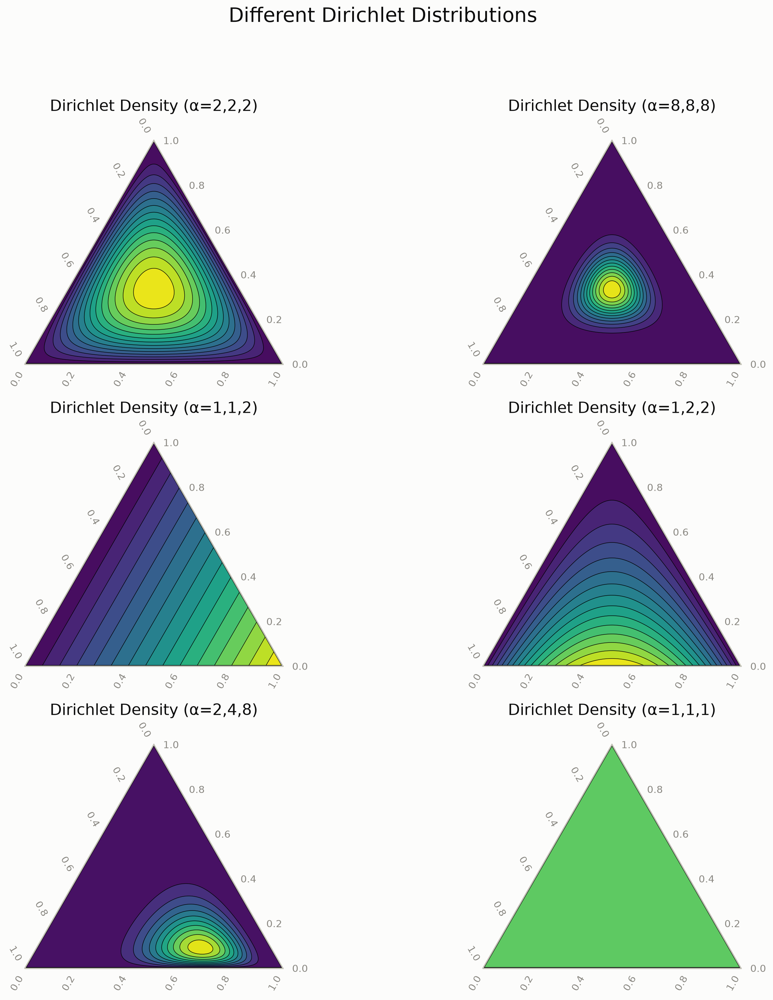

In [ ]:
import mpltern  # noqa: F401  (importing it registers matplotlib's 'ternary' projection)

def dirichlet_pdf(x, y, z, alpha):
    """
    Compute the Dirichlet density for point (x, y, z)
    given parameters alpha = (α1, α2, α3).
    """
    a1, a2, a3 = alpha
    B = scipy.special.gamma(a1) * scipy.special.gamma(a2) * scipy.special.gamma(a3) / scipy.special.gamma(a1 + a2 + a3)
    return x ** (a1 - 1) * y ** (a2 - 1) * z ** (a3 - 1) / B
alpha_list = [((2, 2, 2), 'Dirichlet Density (α=2,2,2)'), ((8, 8, 8), 'Dirichlet Density (α=8,8,8)'), ((1, 1, 2), 'Dirichlet Density (α=1,1,2)'), ((1, 2, 2), 'Dirichlet Density (α=1,2,2)'), ((2, 4, 8), 'Dirichlet Density (α=2,4,8)'), ((1, 1, 1), 'Dirichlet Density (α=1,1,1)')]
N = 200
a_vals = np.linspace(0.0001, 0.9999, N)
b_vals = np.linspace(0.0001, 0.9999, N)
A, B_mesh = np.meshgrid(a_vals, b_vals)
C = 1 - A - B_mesh
mask = C > 0
x_grid = A[mask]
y_grid = B_mesh[mask]
z_grid = C[mask]
_nrows, _ncols = (3, 2)
_fig, _axes = plt.subplots(nrows=_nrows, ncols=_ncols, subplot_kw={'projection': 'ternary'}, figsize=dynamic_figsize(_nrows, _ncols))
for _ax, (_alpha, _title) in zip(_axes.flat, alpha_list):
    densities = dirichlet_pdf(x_grid, y_grid, z_grid, _alpha)
    vertices = [(0, 0, 1), (0, 1, 0), (1, 0, 0), (0, 0, 1)]
    _ax.plot([v[0] for v in vertices], [v[1] for v in vertices], [v[2] for v in vertices], color='k', lw=2)
    triang = _ax.tricontourf(x_grid, y_grid, z_grid, densities, levels=15, cmap='viridis')
    _ax.tricontour(x_grid, y_grid, z_grid, densities, levels=triang.levels, colors='k', linewidths=0.5)
    _ax.grid(False)
    _ax.set_title(_title)
plt.suptitle('Different Dirichlet Distributions', y=1.05)
plt.tight_layout()
plt.gcf()

## Weight Priors in GMM: Small vs. Large $\alpha$

Weight priors directly influence the mixing proportions of the GMM. Here, we compare the effects of setting a very small versus a very large $\alpha$ value:

- **Small $\alpha$:** Leads to a model where few components dominate.
- **Large $\alpha$:** Encourages the model to assign roughly equal weights to all components.

With a Dirichlet prior $\mathrm{Dir}(\alpha_1,\dots,\alpha_K)$ (`weight_concentration_prior`), tgmm's M-step replaces the maximum-likelihood weights $\pi_k = n_k / n$ by the MAP estimate

$$
\pi_k = \frac{n_k + \alpha_k - 1}{n + \sum_j \alpha_j - K}.
$$

Each $\alpha_k$ therefore acts like $\alpha_k - 1$ extra pseudo-observations assigned to component $k$. For $\alpha_k < 1$ the numerator can become negative for sparsely populated components; tgmm clamps the weights to a tiny positive floor so they stay valid.

Each subplot shows the fitted GMM components (ellipses and means) along with the log-likelihood (LL) achieved.

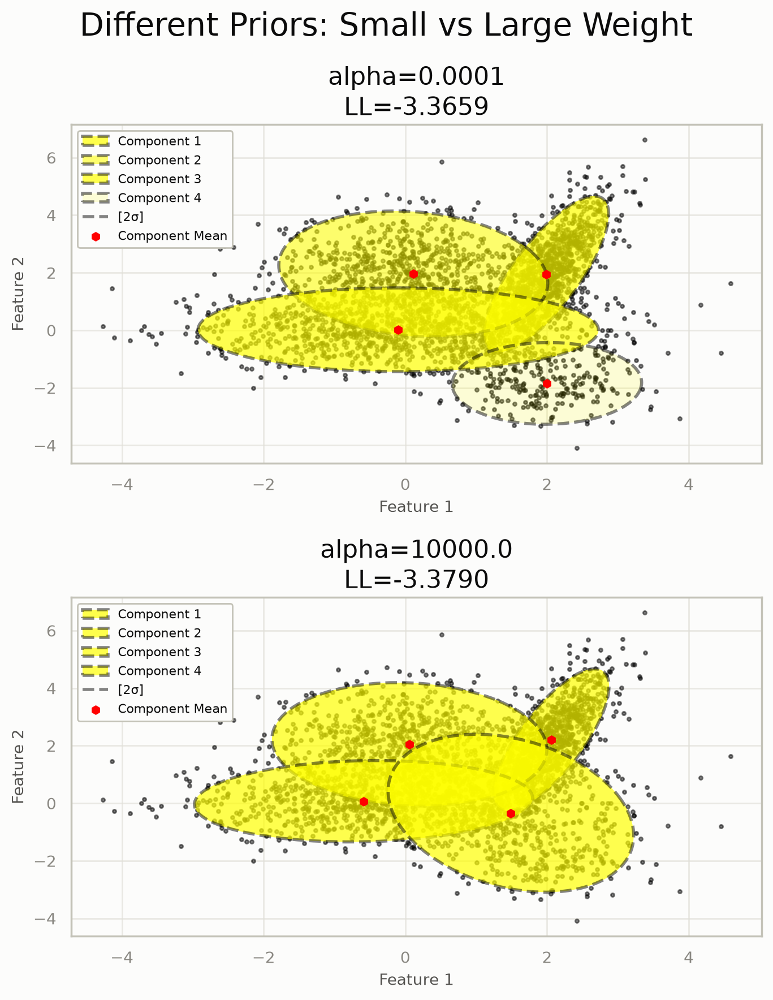

In [ ]:
weigths = np.array([0.0001, 10000.0])
_weights = [torch.tensor([weight], device=device) for weight in weigths]
_nrows, _ncols = (2, 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Different Priors: Small vs Large Weight')
for _ax, _weight in zip(_axs, weigths):
    _gmm_weight_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=MAX_ITER, device=device, weight_concentration_prior=_weight, random_state=SEED, init_means='random')
    _gmm_weight_prior.fit(X_tensor)
    plot_gmm(X=X, gmm=_gmm_weight_prior, ax=_ax, title=f'alpha={_weight.item()}\nLL={_gmm_weight_prior.lower_bound_:.4f}', scale_alpha_by_weight=True, ellipse_line_style='dashed', ellipse_alpha=0.7, scale_size_by_weight=False, ellipse_colors='yellow', ellipse_std_devs=[2], mean_color='red')
plt.tight_layout()
plt.gcf()

## Unbalanced Weight Priors: Dominant Component Effect

In this example, we apply unbalanced weight priors by assigning one component a significantly higher concentration parameter than the others. As expected, the dominant component tends to capture a larger share of the data, which is reflected in both the clustering results and the overall model log-likelihood.

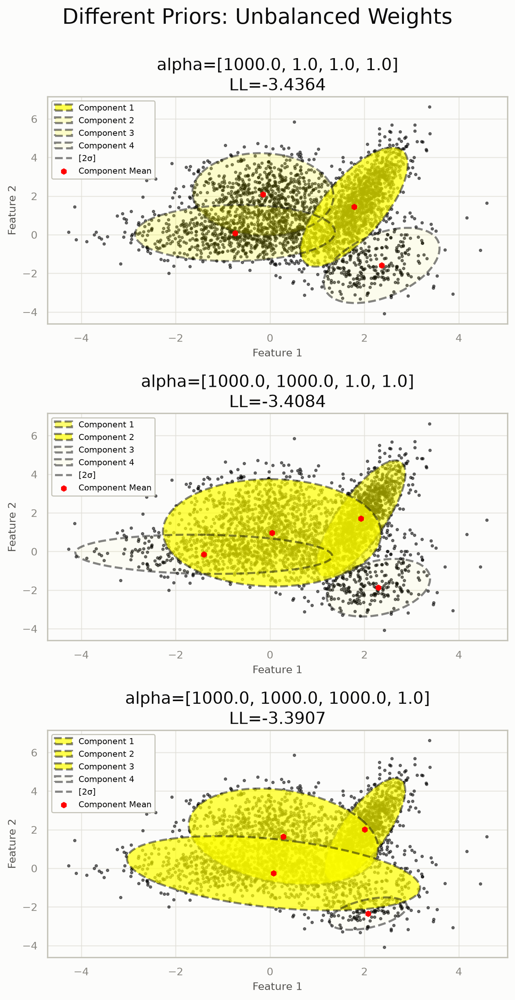

In [ ]:
# Example: One dominant prior and three nearly zero priors.
# Here, we expect the first component to dominate.
weight1 = torch.tensor([1000.0, 1, 1, 1], device=device)
weight2 = torch.tensor([1000.0, 1000.0, 1, 1], device=device)
weight3 = torch.tensor([1000.0, 1000.0, 1000.0, 1], device=device)
_weights = [weight1, weight2, weight3]
_nrows, _ncols = (len(_weights), 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Different Priors: Unbalanced Weights')
for _ax, _weight in zip(_axs, _weights):
    _gmm_weight_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=MAX_ITER, device=device, weight_concentration_prior=_weight, random_state=SEED, init_means='random')
    _gmm_weight_prior.fit(X_tensor)
    plot_gmm(X=X, gmm=_gmm_weight_prior, ax=_ax, title=f'alpha={_weight.tolist()}\nLL={_gmm_weight_prior.lower_bound_:.4f}', scale_alpha_by_weight=True, scale_size_by_weight=False, ellipse_colors='yellow', ellipse_std_devs=[2], ellipse_line_style='dashed', ellipse_alpha=0.7, mean_color='red')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

## Prior on the Means in Gaussian Mixture Models

A **Gaussian prior** on the component means regularizes the model and guides Maximum a Posteriori (MAP) estimation. It keeps the estimated means from drifting too far from a reasonable location, which is particularly useful when the data are noisy or scarce.

### Gaussian Prior on the Means

tgmm uses the form of the mean prior that is conjugate to a Gaussian with covariance $\Sigma_k$:

$$
p(\mu_k \mid \Sigma_k) = \mathcal{N}\!\left(\mu_k;\ \mu_0,\ \tfrac{1}{\kappa_0}\,\Sigma_k\right),
$$

where:
- $\mu_0$ is the **prior mean** (`mean_prior`, often set from a K-means initialization),
- $\kappa_0$ is the **mean precision** (`mean_precision_prior`).

Written this way, the prior's spread scales with the component's own covariance and $\kappa_0$ acts as a number of *pseudo-observations* sitting at $\mu_0$. The MAP M-step update for the mean is

$$
\mu_k = \frac{\sum_i r_{ik}\,x_i + \kappa_0\,\mu_0}{n_k + \kappa_0}
      = \frac{n_k\,\bar y_k + \kappa_0\,\mu_0}{n_k + \kappa_0},
$$

a weighted average of the data mean $\bar y_k$ (weight $n_k$) and the prior mean $\mu_0$ (weight $\kappa_0$).

### Impact of the Mean Precision Prior

- **Weak prior (small $\kappa_0$).** The prior has little influence and the means are determined mostly by the data. This is flexible but can overfit when data are noisy.
- **Strong prior (large $\kappa_0$).** The estimated means are pulled strongly toward $\mu_0$. This helps with limited data or when you have prior knowledge about where the clusters sit, but a very strong prior can prevent the model from adapting to the data.

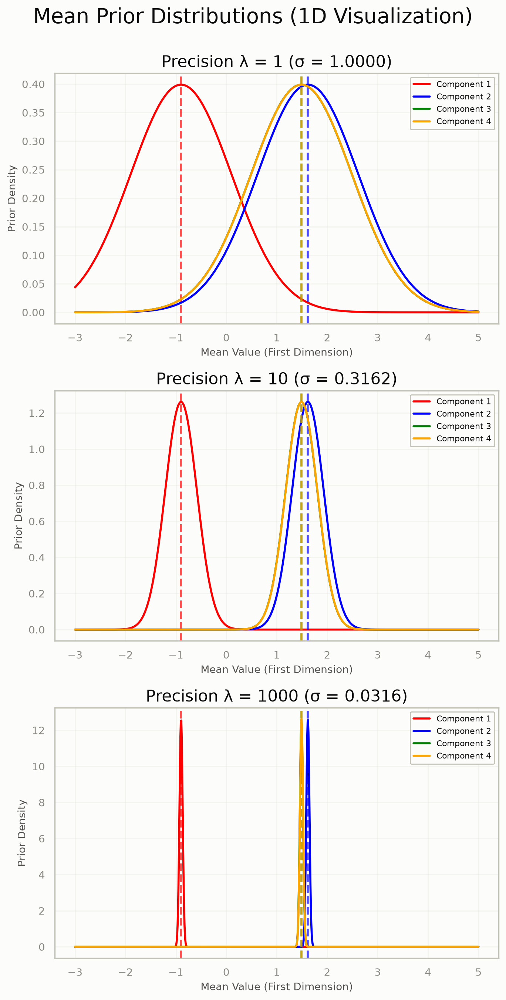

In [ ]:
# Visualize the mean prior distributions as 1D Gaussians
_precision_values = [1, 10, 1000]
_init_means_kmeans = GMMInitializer.kmeans(X_tensor.cpu(), k=n_components)
# Create the initial means using K-means on the CPU
_mean_prior = _init_means_kmeans.clone().to(device)
x_range = np.linspace(-3, 5, 1000)
_nrows, _ncols = (len(_precision_values), 1)
# Create a range for plotting the Gaussian distributions
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Mean Prior Distributions (1D Visualization)', y=1)
colors = ['red', 'blue', 'green', 'orange']
component_labels = [f'Component {i + 1}' for i in range(n_components)]
for _ax, _precision in zip(_axs, _precision_values):
    prior_std = 1.0 / np.sqrt(_precision)
    for _i in range(n_components):
        mean_val = _mean_prior[_i, 0].cpu().numpy()
        gaussian_pdf = 1 / (prior_std * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x_range - mean_val) / prior_std) ** 2)
        _ax.plot(x_range, gaussian_pdf, color=colors[_i], linewidth=2, label=f'{component_labels[_i]}')
        _ax.axvline(mean_val, color=colors[_i], linestyle='--', alpha=0.7)  # Standard deviation of the prior (inverse of precision)
    _ax.set_title(f'Precision λ = {_precision} (σ = {prior_std:.4f})')
    _ax.set_xlabel('Mean Value (First Dimension)')
    _ax.set_ylabel('Prior Density')  # Plot Gaussian distributions for each component's mean prior
    _ax.legend(loc='upper right')
    _ax.grid(True, alpha=0.3)  # Use the first dimension of the mean for visualization
plt.tight_layout()
plt.gcf()

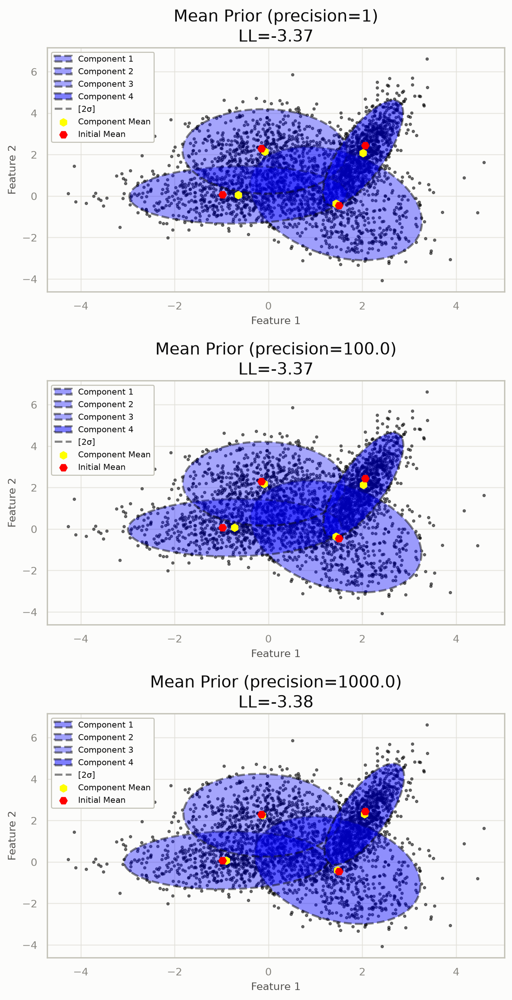

In [ ]:
# Define a list of precision values to compare
_precision_values = [1, 100.0, 1000.0]
_init_means_kmeans = GMMInitializer.kmeans(X_tensor.cpu(), k=n_components)
# Create the initial means using K-means on the CPU
_mean_prior = _init_means_kmeans.clone().to(device)
_nrows, _ncols = (len(_precision_values), 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
for _ax, _precision in zip(_axs, _precision_values):
    gmm_mean_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=MAX_ITER, device=device, mean_prior=_mean_prior, mean_precision_prior=_precision, random_state=SEED, init_means=_mean_prior)
    gmm_mean_prior.fit(X_tensor)
    _title = f'Mean Prior (precision={_precision})\nLL={gmm_mean_prior.lower_bound_:.2f}'
    plot_gmm(X=X, gmm=gmm_mean_prior, ax=_ax, title=_title, ellipse_alpha=0.5, ellipse_line_style='dashed', show_initial_means=True, ellipse_colors='blue', ellipse_std_devs=[2], mean_color='yellow', mean_size=50, initial_mean_size=50, scale_alpha_by_weight=True, scale_size_by_weight=False)  # Create a new GMM instance for each precision value
    _ax.legend()
plt.tight_layout()
plt.gcf()

## The Gamma Distribution and its Inverse

The Gamma distribution is given by the density function

$$
f(x; \alpha, \theta) = \frac{1}{\Gamma(\alpha)\,\theta^\alpha}\, x^{\alpha-1} \exp\left(-\frac{x}{\theta}\right), \quad x > 0,
$$

where:
- $\alpha$ is the **shape parameter**,
- $\theta$ is the **scale parameter**,
- $\Gamma(\alpha)$ is the gamma function.

The mean of the Gamma distribution is

$$
E[X] = \alpha \theta.
$$

If we define

$$
Y = \frac{1}{X},
$$

then using the standard transformation method the density of $Y$ becomes

$$
\begin{aligned}
f_Y(y) &= f_X\left(\frac{1}{y}\right) \left|\frac{d}{dy}\left(\frac{1}{y}\right)\right| \\
&= \frac{1}{\Gamma(\alpha)\,\theta^\alpha} \left(\frac{1}{y}\right)^{\alpha-1} \exp\left(-\frac{1}{\theta y}\right) \frac{1}{y^2} \\
&= \frac{1}{\Gamma(\alpha)\,\theta^\alpha}\, y^{-\alpha-1} \exp\left(-\frac{1}{\theta y}\right), \quad y > 0.
\end{aligned}
$$

This density is of the form of an inverse Gamma distribution. A standard parameterization for the inverse Gamma distribution is:

$$
f_Y(y; \alpha, \beta) = \frac{\beta^\alpha}{\Gamma(\alpha)}\, y^{-\alpha-1} \exp\left(-\frac{\beta}{y}\right), \quad y > 0,
$$

where $\beta > 0$ is the **scale parameter** of the inverse Gamma. By comparing the two forms, we identify

$$
\beta^\alpha = \frac{1}{\theta^\alpha} \quad \Longrightarrow \quad \beta = \frac{1}{\theta}.
$$

### Mean of the Inverse Gamma Distribution

For the inverse Gamma distribution with parameters $\alpha$ and $\beta$, the mean exists for $\alpha > 1$ and is given by

$$
E[Y] = \frac{\beta}{\alpha - 1}.
$$

Substituting $\beta = \frac{1}{\theta}$ into the formula, we get

$$
E[Y] = \frac{1/\theta}{\alpha - 1} = \frac{1}{\theta (\alpha - 1)}.
$$

### Impact of the Parameters

- **Shape ($\alpha$)**:
  The shape parameter $\alpha$ affects the tail behavior and the concentration of the distribution. Increasing $\alpha$ (with $\beta$ fixed) causes both the mean and the mode to decrease:

  $$
  E[Y] = \frac{\beta}{\alpha - 1}, \qquad \text{mode} = \frac{\beta}{\alpha + 1}.
  $$

  Thus, a higher $\alpha$ results in a distribution that is more concentrated near zero and has lighter tails, while a lower $\alpha$ produces heavier tails.

- **Scale ($\beta$)**:
  The scale parameter $\beta$ shifts the distribution. A larger $\beta$ leads to higher values of the mean and mode. In many Bayesian contexts, the inverse gamma is obtained by inverting a Gamma-distributed variable with scale parameter $\theta$, where $\beta = \frac{1}{\theta}$. In that case, increasing $\theta$ (making the Gamma distribution more spread out) results in a smaller $\beta$, which in turn shifts the inverse gamma distribution toward lower values.

## Visualizing the Inverse Gamma Distribution

The three panels below demonstrate the following scenarios:

1. **Varying $\alpha$ with Fixed $\theta$:**
   How changes in the shape parameter alter the spread and concentration of the distribution.

2. **Fixed $\alpha$ with Varying $\theta$:**
   The effect of the scale parameter on the location and spread of the distribution.

3. **Varying Both to Maintain the Same Mode:**
   How different combinations of $\alpha$ and $\theta$ can yield the same mode, illustrating the trade-off between the parameters.

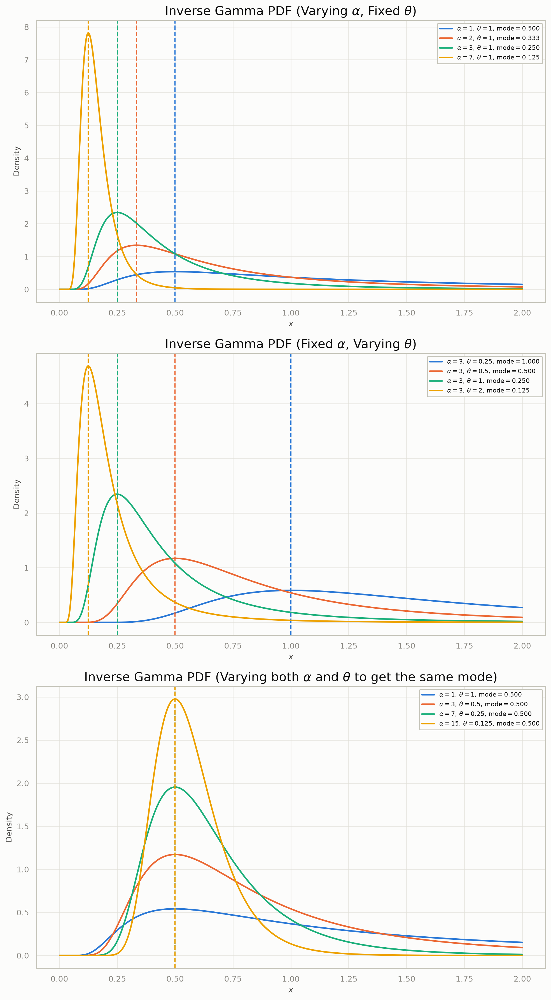

In [ ]:
_x = np.linspace(0.001, 2, 1000)
_fig, _axes = plt.subplots(3, 1, figsize=(10, 18))
fixed_theta = 1
alphas = [1, 2, 3, 7]
# -------------------------------
# Plot 1: Varying $\alpha$, fixed $\theta$
for _alpha in alphas:
    beta = 1 / fixed_theta
    pdf_vals = invgamma.pdf(_x, a=_alpha, scale=beta)
    mode = beta / (_alpha + 1)
    line, = _axes[0].plot(_x, pdf_vals, label=f'$\\alpha={_alpha},\\,\\theta={fixed_theta},\\,\\mathrm{{mode}}={mode:.3f}$')
    _axes[0].axvline(mode, linestyle='dashed', color=line.get_color(), linewidth=1.5)
_axes[0].set_title('Inverse Gamma PDF (Varying $\\alpha$, Fixed $\\theta$)')
_axes[0].set_xlabel('$x$')
_axes[0].set_ylabel('Density')
_axes[0].legend()
_axes[0].grid(True)
fixed_alpha = 3
thetas = [0.25, 0.5, 1, 2]
for theta in thetas:
    beta = 1 / theta
    pdf_vals = invgamma.pdf(_x, a=fixed_alpha, scale=beta)
    mode = beta / (fixed_alpha + 1)
    line, = _axes[1].plot(_x, pdf_vals, label=f'$\\alpha={fixed_alpha},\\,\\theta={theta},\\,\\mathrm{{mode}}={mode:.3f}$')
    _axes[1].axvline(mode, linestyle='dashed', color=line.get_color(), linewidth=1.5)
# Plot 2: Fixed $\alpha$, varying $\theta$
_axes[1].set_title('Inverse Gamma PDF (Fixed $\\alpha$, Varying $\\theta$)')
_axes[1].set_xlabel('$x$')
_axes[1].set_ylabel('Density')
_axes[1].legend()
_axes[1].grid(True)
alphas_equal = [1, 3, 7, 15]
thetas_equal = [1, 0.5, 0.25, 0.125]
for _alpha, theta in zip(alphas_equal, thetas_equal):
    beta = 1 / theta
    pdf_vals = invgamma.pdf(_x, a=_alpha, scale=beta)
    mode = beta / (_alpha + 1)
    line, = _axes[2].plot(_x, pdf_vals, label=f'$\\alpha={_alpha},\\,\\theta={theta},\\,\\mathrm{{mode}}={mode:.3f}$')
    _axes[2].axvline(mode, linestyle='dashed', color=line.get_color(), linewidth=1.5)
_axes[2].set_title('Inverse Gamma PDF (Varying both $\\alpha$ and $\\theta$ to get the same mode)')
_axes[2].set_xlabel('$x$')
_axes[2].set_ylabel('Density')
_axes[2].legend()
_axes[2].grid(True)
plt.tight_layout()
# Plot 3: Varying both $\alpha$ and $\theta$ to get the same mode
plt.gcf()

## The Wishart Distribution and its Inverse

In Bayesian modeling of Gaussian mixtures, a key step is placing a prior on the covariance matrices of each Gaussian component. Since these matrices must be positive-definite (i.e., all eigenvalues are positive), the prior must respect this constraint. While the (non-inverse) Wishart distribution is a natural multivariate analogue of the Gamma distribution, it has characteristics that are not ideal for covariance priors in a MAP estimation context. Instead, the **inverse Wishart** (and its one-dimensional counterpart, the **inverse Gamma**) is commonly used. Let’s explore why.

### From the Gamma to the Wishart Distribution

#### The Gamma Distribution (Scalar Case)

The Gamma distribution is defined as

$$
f(x; \alpha, \theta) = \frac{1}{\Gamma(\alpha)\,\theta^\alpha}\, x^{\alpha-1} \exp\left(-\frac{x}{\theta}\right), \quad x > 0,
$$

where:
- $ \alpha $ is the **shape parameter**,
- $ \theta $ is the **scale parameter**, and
- $ \Gamma(\alpha) $ is the Gamma function.

For many Bayesian models, the Gamma distribution is used as a conjugate prior for positive parameters (e.g. precision). Notice that—even though certain parameter choices can put high density near zero—its support is strictly $ (0, \infty) $, so the probability of $ x=0 $ is exactly zero.

#### The Wishart Distribution (Multivariate Case)

When we generalize to matrices, the Wishart distribution arises naturally. Its density over $ d \times d $ positive-definite matrices is

$$
p(\mathbf{S}; \nu, \Psi) \propto |\mathbf{S}|^{\frac{\nu-d-1}{2}} \exp\left(-\frac{1}{2}\operatorname{tr}\left(\Psi^{-1} \mathbf{S}\right)\right),
$$

where:
- $ \mathbf{S} $ is a positive-definite matrix,
- $ \nu $ is the **degrees of freedom** (playing a role similar to the shape parameter),
- $ \Psi $ is the **scale matrix**, and
- $ d $ is the dimension.

For $ d = 1 $, the Wishart reduces to the Gamma distribution (up to constants), which shows their close connection.

### Why Use the Inverse Wishart and Inverse Gamma?

There are two main reasons for preferring the inverse distributions as priors on covariance matrices in a GMM:

**The Density Vanishes at Zero**

A Gamma density with shape $\alpha \le 1$ (or a Wishart density with $\nu \le d+1$) does not vanish near zero -- it can even diverge there -- so a Gamma or Wishart prior placed on a variance or covariance can favor degenerate, near-zero values. The inverse Gamma and inverse Wishart densities go to zero as $y \to 0$ (exponentially fast, through the $\exp(-\beta/y)$ factor; for matrices, as $\Sigma$ approaches singularity). The prior itself therefore rules out collapsed components, which is crucial for well-defined Gaussian likelihoods.

**Longer Right-Hand Tail**

The inverse distributions typically have a heavier (longer) tail on the right-hand side. This longer tail means that while the prior penalizes extremely small covariances (preventing singularity), it is more tolerant of large covariance estimates.

For covariance matrices, this is important because the empirical covariance can vary widely—especially in high-dimensional settings. The long tail ensures that the prior does not overly constrain large values, thus preserving flexibility. In 2D, for example, the determinant of the covariance matrix (which is proportional to the area of the corresponding ellipse) can be thought of as capturing the “size” of the uncertainty. A heavy right tail in the inverse Wishart better accommodates the possibility of large uncertainty, similar in spirit (though not strictly proportional) to how the surface area of a circle increases with its radius.

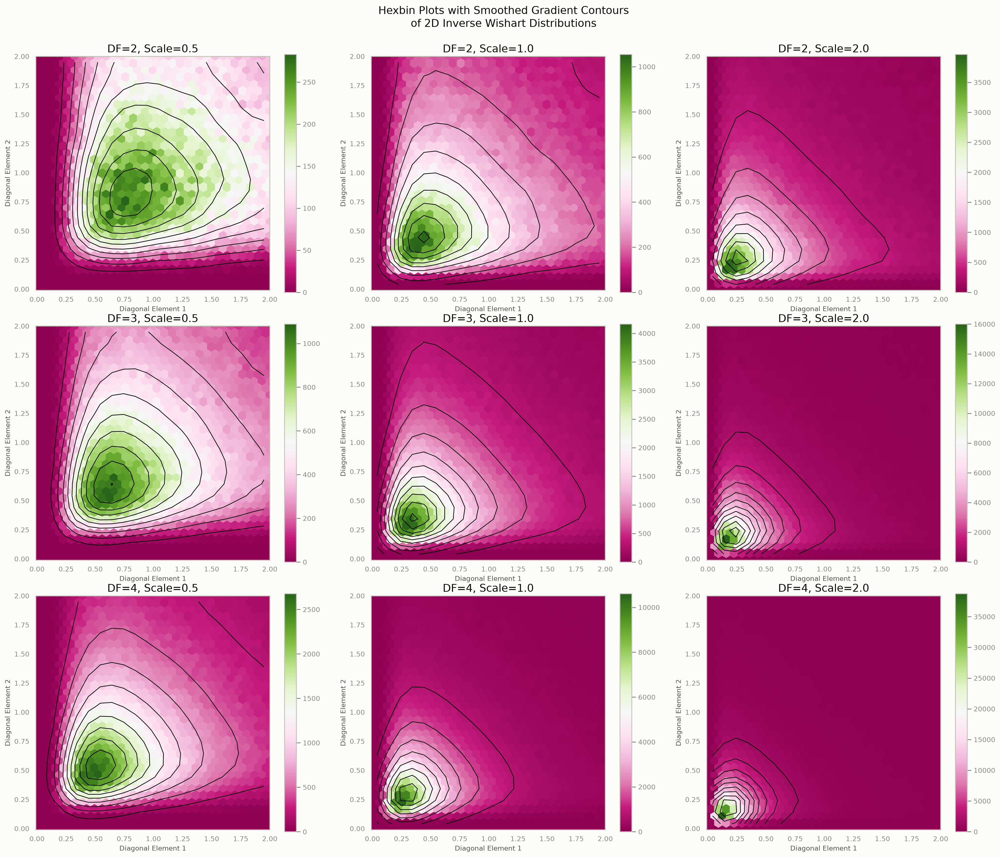

In [ ]:
covariance_matrix = np.array([[1, 0.5], [0.5, 1]])
dfs = [2, 3, 4]
scales = [0.5, 1, 2]
scale_matrices = [covariance_matrix * scale for scale in scales]
inv_wishart_samples_list = []
for df in dfs:
    for scale_matrix in scale_matrices:
        _samples = wishart.rvs(df=df, scale=scale_matrix, size=1000000)
        inv_samples = np.linalg.inv(_samples)
        inv_wishart_samples_list.append((df, scale_matrix, inv_samples))
xmin, xmax = (-0.01, 2)
ymin, ymax = (-0.01, 2)
_nrows, _ncols = (len(dfs), len(scale_matrices))
_figsize = dynamic_figsize(_nrows, _ncols, base_width=7, base_height=6)
_fig, _axes = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Hexbin Plots with Smoothed Gradient Contours\nof 2D Inverse Wishart Distributions', fontsize=16)
idx = 0
for _i, df in enumerate(dfs):
    for _j, scale_matrix in enumerate(scale_matrices):
        df_current, scale_matrix_current, inv_samples = inv_wishart_samples_list[idx]
        idx = idx + 1
        _x = inv_samples[:, 0, 0]
        y = inv_samples[:, 1, 1]
        _ax = _axes[_i, _j]
        hb = _ax.hexbin(_x, y, gridsize=30, cmap='PiYG', extent=[xmin, xmax, ymin, ymax])
        _fig.colorbar(hb, ax=_ax, orientation='vertical')
        H, xedges, yedges = np.histogram2d(_x, y, bins=20, range=[[xmin, xmax], [ymin, ymax]])
        H_smooth = gaussian_filter(H, sigma=1)
        Xc = (xedges[:-1] + xedges[1:]) / 2
        Yc = (yedges[:-1] + yedges[1:]) / 2
        X_mesh, Y_mesh = np.meshgrid(Xc, Yc)
        _ax.contour(X_mesh, Y_mesh, H_smooth.T, colors='k', linewidths=1, alpha=1, levels=10)
        _ax.set_aspect('equal')
        _ax.set_xlim([xmin, xmax])
        _ax.set_ylim([ymin, ymax])
        _ax.set_title(f'DF={df}, Scale={np.round(scale_matrix[0, 0], 1)}')
        _ax.set_xlabel('Diagonal Element 1')
        _ax.set_ylabel('Diagonal Element 2')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

## Covariance Priors in GMM

Next, we demonstrate how covariance priors affect the GMM. In the following three sections, we vary:

1. **Prior Strength:** The covariance prior is scaled by different factors.
2. **Degrees of Freedom (DOF):** The DOF of the prior distribution is varied.
3. **Strength and DOF:** Varying both the prior strength and the DOF.

### 1. Varying Prior Strength

Here, the DOF is fixed and the covariance prior strength is varied.
### How the covariance prior enters the M-step

With an inverse-Wishart prior $\Sigma_k \sim \mathcal{IW}(\Psi_0, \nu_0)$ (`covariance_prior` $=\Psi_0$, `degrees_of_freedom_prior` $=\nu_0$), tgmm's MAP covariance update for `covariance_type='full'` is

$$
\Sigma_k = \frac{\Psi_0 + \sum_i r_{ik}(x_i-\mu_k)(x_i-\mu_k)^\top + \text{(mean-shrinkage term)} + \varepsilon I}{\nu_0 + n_k},
$$

where the mean-shrinkage term only appears when a mean prior is supplied as well, and $\varepsilon$ is `reg_covar`. Read it as a weighted average: the prior contributes $\nu_0$ pseudo-observations with total scatter $\Psi_0$, so the prior's best guess for $\Sigma_k$ is $\Psi_0/\nu_0$. To encode a prior covariance guess $\Sigma^{\ast}$ with strength $\nu_0$, pass `covariance_prior`$=\nu_0\,\Sigma^{\ast}$.

!!! note
    The denominator is $\nu_0 + n_k$, not the textbook inverse-Wishart posterior mode $\nu_0 + n_k + d + 1$ (nor the mean's $\nu_0 + n_k - d - 1$). tgmm deliberately uses the simple ratio $\Psi_n/\nu_n$: unlike the textbook formulas it stays finite and positive for every $\nu_n > 0$, and the two agree closely when $\nu_n \gg d$.

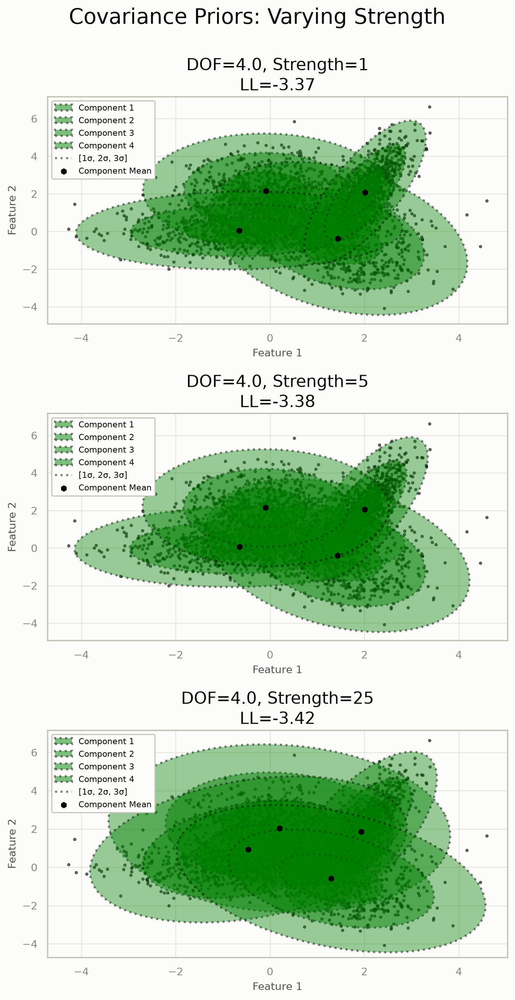

In [ ]:
_data_covariance = np.cov(X_tensor.cpu().numpy(), rowvar=False)  # shape (2, 2)
_data_covariance = torch.tensor(_data_covariance, dtype=torch.float32, device=device)
_data_covariance = _data_covariance.unsqueeze(0).expand(n_components, -1, -1)
degrees_of_freedom_prior = float(n_features + 2)
_prior_strengths = [1, 5, 25]
_nrows, _ncols = (len(_prior_strengths), 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Covariance Priors: Varying Strength')
for _ax, _strength in zip(_axs, _prior_strengths):
    _cov_prior = _data_covariance * _strength
    _dummy_mean_prior = torch.zeros(n_components, n_features, device=device)
    _dummy_mean_precision_prior = 1e-10
    _gmm_cov_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=10 * MAX_ITER, device=device, covariance_prior=_cov_prior, degrees_of_freedom_prior=degrees_of_freedom_prior, mean_prior=_dummy_mean_prior, mean_precision_prior=_dummy_mean_precision_prior)
    _gmm_cov_prior.fit(X_tensor)
    _title = f'DOF={degrees_of_freedom_prior}, Strength={_strength}\nLL={_gmm_cov_prior.lower_bound_:.2f}'
    plot_gmm(X=X, gmm=_gmm_cov_prior, ax=_ax, title=_title, ellipse_colors='green', ellipse_std_devs=[1, 2, 3])  # effectively no strong push on means
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

### 2. Varying Degrees of Freedom (DOF)

Here, the covariance prior strength is fixed and we vary the DOF.

Note: For 2D, DOF must be greater than 1.

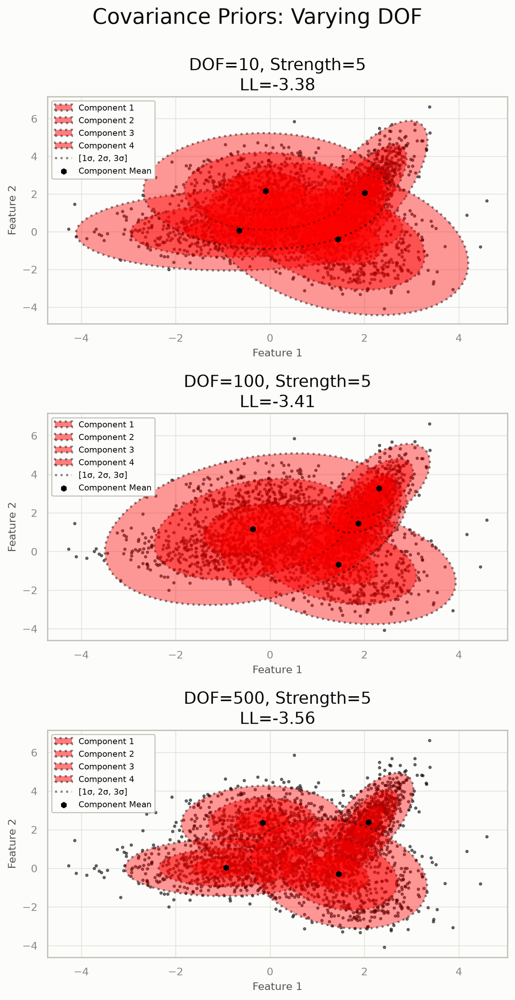

In [ ]:
_data_covariance = np.cov(X_tensor.cpu().numpy(), rowvar=False)  # shape (2, 2)
_data_covariance = torch.tensor(_data_covariance, dtype=torch.float32, device=device)
_data_covariance = _data_covariance.unsqueeze(0).expand(n_components, -1, -1)
_dof_values = [n_features + 8, n_features + 98, n_features + 498]
# Instead of varying strength, we fix the strength and vary DOF.
fixed_strength = 5
_nrows, _ncols = (len(_dof_values), 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Covariance Priors: Varying DOF')
for _ax, _dof in zip(_axs, _dof_values):
    _cov_prior = _data_covariance * fixed_strength
    _dummy_mean_prior = torch.zeros(n_components, n_features, device=device)
    _dummy_mean_precision_prior = 1e-10
    _gmm_cov_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=10 * MAX_ITER, device=device, covariance_prior=_cov_prior, degrees_of_freedom_prior=_dof, mean_prior=_dummy_mean_prior, mean_precision_prior=_dummy_mean_precision_prior)
    _gmm_cov_prior.fit(X_tensor)
    _title = f'DOF={_dof}, Strength={fixed_strength}\nLL={_gmm_cov_prior.lower_bound_:.2f}'
    plot_gmm(X=X, gmm=_gmm_cov_prior, ax=_ax, title=_title, ellipse_colors='red', ellipse_std_devs=[1, 2, 3])  # negligible influence on means
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

### 3. Varying Strength and Degrees of Freedom

Here, both the covariance prior strength and the DOF are varied.

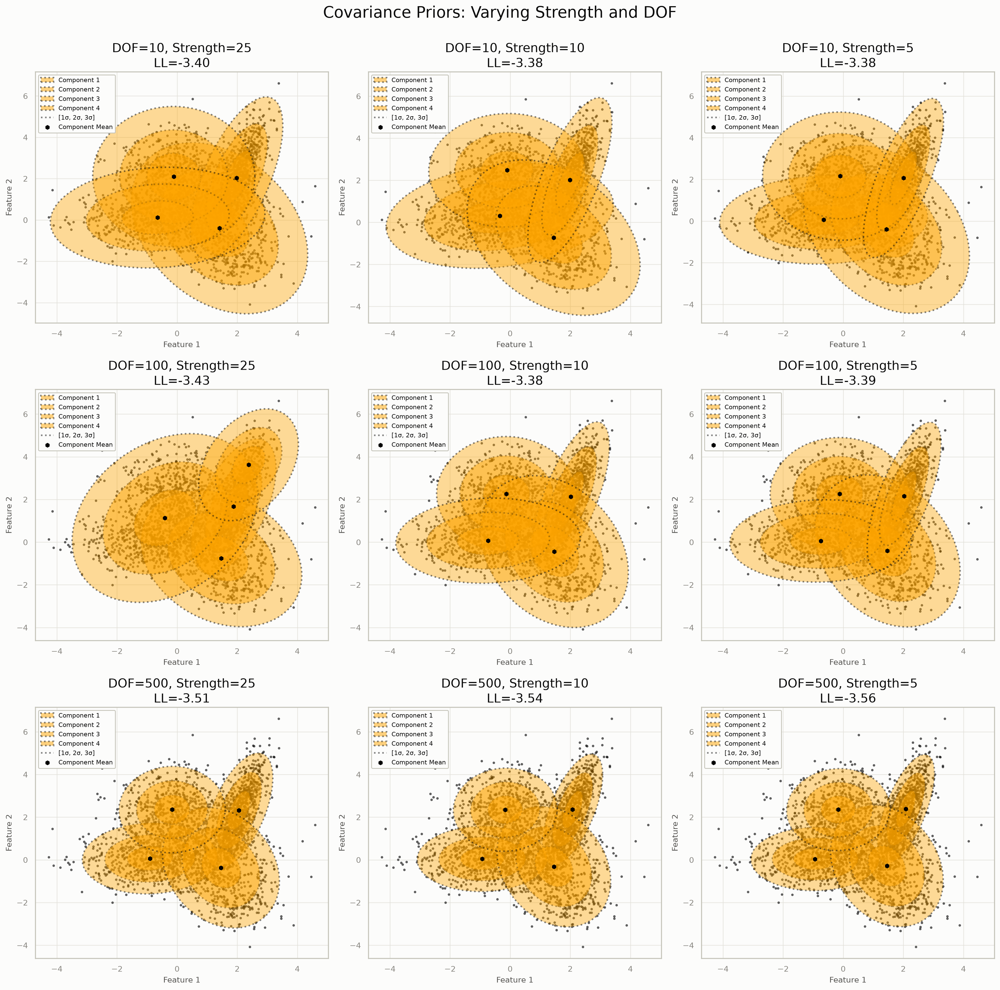

In [ ]:
# Compute data covariance from the tensor data.
_data_covariance = np.cov(X_tensor.cpu().numpy(), rowvar=False)  # shape (2, 2)
_data_covariance = torch.tensor(_data_covariance, dtype=torch.float32, device=device)
_data_covariance = _data_covariance.unsqueeze(0).expand(n_components, -1, -1)
_prior_strengths = [25, 10, 5]
# Define the lists of prior strengths and degrees of freedom to explore.
_dof_values = [n_features + 8, n_features + 98, n_features + 498]
_nrows, _ncols = (len(_dof_values), len(_prior_strengths))
_figsize = dynamic_figsize(_nrows, _ncols, base_width=6, base_height=6)
# Create a 3x3 grid.
_fig, _axs = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
_fig.suptitle('Covariance Priors: Varying Strength and DOF')
for _i, _dof in enumerate(_dof_values):
    for _j, _strength in enumerate(_prior_strengths):
        _ax = _axs[_i, _j]
# Loop over DOF values (rows) and prior strengths (columns)
        _cov_prior = _data_covariance * _strength
        _dummy_mean_prior = torch.zeros(n_components, n_features, device=device)
        _dummy_mean_precision_prior = 1e-10
        _gmm_cov_prior = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=10 * MAX_ITER, device=device, covariance_prior=_cov_prior, degrees_of_freedom_prior=_dof, mean_prior=_dummy_mean_prior, mean_precision_prior=_dummy_mean_precision_prior)  # Compute covariance prior for this combination.
        _gmm_cov_prior.fit(X_tensor)
        _title = f'DOF={_dof}, Strength={_strength}\nLL={_gmm_cov_prior.lower_bound_:.2f}'
        plot_gmm(X=X, gmm=_gmm_cov_prior, ax=_ax, title=_title, ellipse_colors='orange', ellipse_std_devs=[1, 2, 3])
plt.tight_layout(rect=[0, 0, 1, 0.98])  # negligible influence on means
plt.gcf()

## Normal-Inverse-Wishart (NIW) Conjugate Prior

The Normal-Inverse-Wishart (NIW) prior is a **conjugate prior** for the parameters of a multivariate Gaussian distribution when both the mean $\boldsymbol{\mu}$ and covariance matrix $\boldsymbol{\Sigma}$ are unknown. This is fundamentally different from specifying separate priors for means and covariances.

### Mathematical Formulation

For a multivariate Gaussian component with parameters $(\boldsymbol{\mu}, \boldsymbol{\Sigma})$, the NIW prior is defined as:

$$p(\boldsymbol{\mu}, \boldsymbol{\Sigma}^{-1}) = \mathcal{N}\!\left(\boldsymbol{\mu} \,\middle|\, \boldsymbol{m}_0, \tfrac{1}{\lambda_0}\boldsymbol{\Sigma}\right) \cdot \mathcal{W}(\boldsymbol{\Sigma}^{-1} | \nu_0, \boldsymbol{\Psi}_0^{-1})$$

Where:
- $\boldsymbol{m}_0$: prior mean (hyperparameter)
- $\lambda_0$: prior precision parameter (`mean_precision_prior`; controls how tightly the mean is constrained around $\boldsymbol{m}_0$ -- the prior covariance of $\boldsymbol{\mu}$ is $\boldsymbol{\Sigma}/\lambda_0$)
- $\nu_0$: degrees of freedom for the Wishart distribution (`degrees_of_freedom_prior`)
- $\boldsymbol{\Psi}_0$: scale matrix for the Wishart distribution (`covariance_prior`)

### Key Properties of NIW Prior

1. **Conjugacy**: The posterior distribution is also NIW, making Bayesian inference analytically tractable.

2. **Coupling**: The mean and covariance are coupled through the precision parameter $\lambda_0$. When $\boldsymbol{\Sigma}$ is large (uncertain), the mean prior becomes less informative automatically.

3. **Natural Parameterization**: The NIW prior naturally captures the relationship between mean uncertainty and covariance uncertainty.

### Posterior Updates in tgmm

Given the effective sample count $n_k$, data mean $\bar y_k$ and scatter $W_k = \sum_i r_{ik}(x_i-\bar y_k)(x_i-\bar y_k)^\top$ of component $k$, the NIW posterior parameters are

$$
\lambda_n = \lambda_0 + n_k, \qquad \nu_n = \nu_0 + n_k, \qquad
\boldsymbol{m}_n = \frac{\lambda_0 \boldsymbol{m}_0 + n_k \bar y_k}{\lambda_0 + n_k},
$$

$$
\boldsymbol{\Psi}_n = \boldsymbol{\Psi}_0 + W_k + \frac{\lambda_0 n_k}{\lambda_0 + n_k}(\bar y_k - \boldsymbol{m}_0)(\bar y_k - \boldsymbol{m}_0)^\top .
$$

tgmm sets $\mu_k = \boldsymbol{m}_n$ and $\Sigma_k = \boldsymbol{\Psi}_n / \nu_n$ (plus `reg_covar` on the diagonal of $\boldsymbol{\Psi}_n$). This is *not* the textbook inverse-Wishart posterior mean $\boldsymbol{\Psi}_n/(\nu_n - d - 1)$, which is undefined once $\nu_n \le d + 1$; the plain ratio stays finite and positive for any $\nu_n > 0$.

### Why NIW ≠ Separate Mean + Covariance Priors

When using **separate priors**:
- Mean prior: $p(\boldsymbol{\mu}) = \mathcal{N}(\boldsymbol{\mu} | \boldsymbol{m}_0, \tau_0^2 \mathbf{I})$
- Covariance prior: $p(\boldsymbol{\Sigma}^{-1}) = \mathcal{W}(\boldsymbol{\Sigma}^{-1} | \nu_0, \boldsymbol{\Psi}_0^{-1})$

The key differences are:

1. **Independence vs. Coupling**: Separate priors assume independence between mean and covariance uncertainty, while NIW couples them naturally.

2. **Prior Strength Interpretation**: In NIW, $\lambda_0$ controls how much the mean prior strength depends on the current covariance estimate. In separate priors, mean and covariance prior strengths are fixed independently.

3. **Bayesian Updates**: NIW updates both parameters simultaneously with proper coupling, while separate priors update them independently.

In tgmm, supplying only `mean_prior` leaves the covariance update as maximum likelihood, supplying only `covariance_prior` leaves the mean update as maximum likelihood, and supplying both switches to the joint NIW update above.

### Demonstration

We'll compare three scenarios:
1. **Mean Prior Only**: Prior on means, MLE for covariances
2. **Covariance Prior Only**: Prior on covariances, MLE for means
3. **NIW Prior**: Coupled prior on both parameters

This will highlight how the coupling in NIW differs from independent priors.

NIW Hyperparameters:
λ₀ (precision parameter): 10
ν₀ (degrees of freedom): 102
m₀ (prior mean): [0. 0.]
Ψ₀ (scale matrix): 
[[10.  0.]
 [ 0. 10.]]


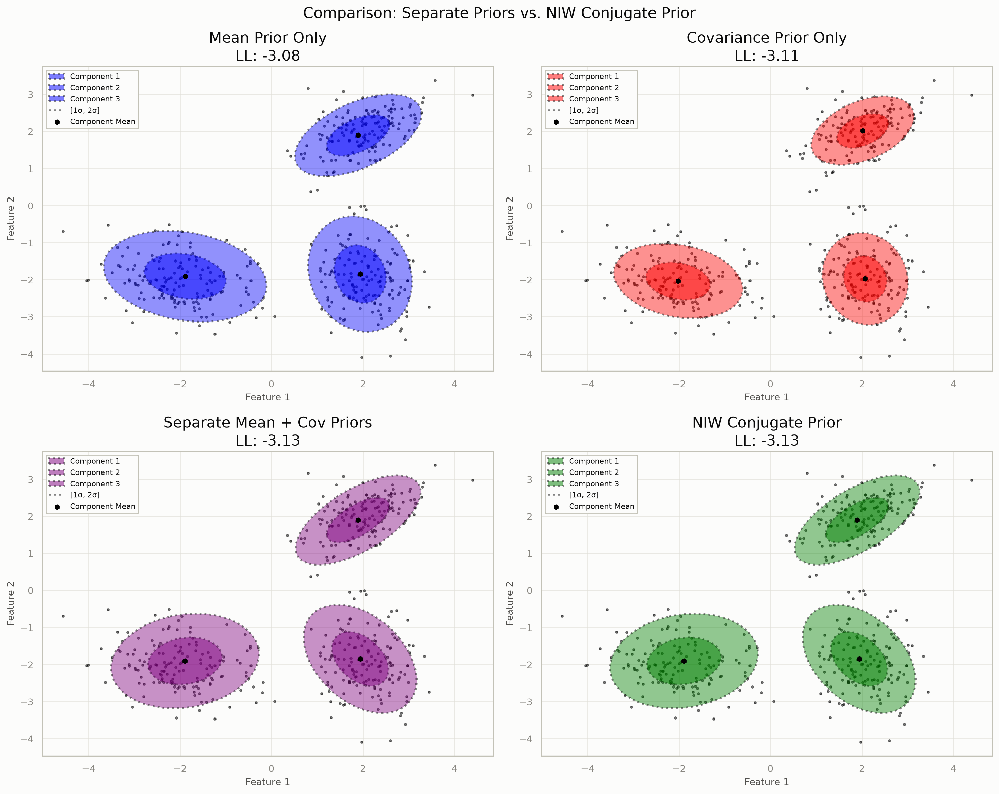

In [ ]:
np.random.seed(42)
torch.manual_seed(42)
n_samples_per_component = 150
true_means = np.array([[2.0, 2.0], [-2.0, -2.0], [2.0, -2.0]])
true_covs = np.array([[[0.5, 0.2], [0.2, 0.3]], [[0.8, -0.1], [-0.1, 0.4]], [[0.3, 0.0], [0.0, 0.6]]])
X_list = []
for _i, (mean, _cov) in enumerate(zip(true_means, true_covs)):
    X_component = np.random.multivariate_normal(mean, _cov, n_samples_per_component)
    X_list.append(X_component)
X_1 = np.vstack(X_list)
X_tensor_1 = torch.tensor(X_1, dtype=torch.float32, device=device)
_n_samples, _n_features = X_1.shape
_n_components = 3
lambda0 = 10
nu0 = _n_features + 100
m0 = torch.zeros(_n_components, _n_features, device=device)
Psi0 = torch.eye(_n_features, device=device).unsqueeze(0).expand(_n_components, -1, -1) * 10
print('NIW Hyperparameters:')
print(f'λ₀ (precision parameter): {lambda0}')
print(f'ν₀ (degrees of freedom): {nu0}')
print(f'm₀ (prior mean): {m0[0].cpu().numpy()}')
print(f'Ψ₀ (scale matrix): \n{Psi0[0].cpu().numpy()}')
_fig, _axes = plt.subplots(2, 2, figsize=(15, 12))
_fig.suptitle('Comparison: Separate Priors vs. NIW Conjugate Prior', fontsize=16)
_ax = _axes[0, 0]
gmm_mean_only = GaussianMixture(n_features=_n_features, n_components=_n_components, covariance_type='full', max_iter=MAX_ITER, device=device, mean_prior=m0, mean_precision_prior=lambda0)
gmm_mean_only.fit(X_tensor_1)
plot_gmm(X=X_1, gmm=gmm_mean_only, ax=_ax, title=f'Mean Prior Only\nLL: {gmm_mean_only.lower_bound_:.2f}', ellipse_colors='blue', ellipse_std_devs=[1, 2])
_ax = _axes[0, 1]
gmm_cov_only = GaussianMixture(n_features=_n_features, n_components=_n_components, covariance_type='full', max_iter=MAX_ITER, device=device, covariance_prior=Psi0, degrees_of_freedom_prior=nu0)
gmm_cov_only.fit(X_tensor_1)
plot_gmm(X=X_1, gmm=gmm_cov_only, ax=_ax, title=f'Covariance Prior Only\nLL: {gmm_cov_only.lower_bound_:.2f}', ellipse_colors='red', ellipse_std_devs=[1, 2])
_ax = _axes[1, 0]
gmm_separate = GaussianMixture(n_features=_n_features, n_components=_n_components, covariance_type='full', max_iter=MAX_ITER, device=device, mean_prior=m0, mean_precision_prior=lambda0, covariance_prior=Psi0, degrees_of_freedom_prior=nu0)
gmm_separate.fit(X_tensor_1)
plot_gmm(X=X_1, gmm=gmm_separate, ax=_ax, title=f'Separate Mean + Cov Priors\nLL: {gmm_separate.lower_bound_:.2f}', ellipse_colors='purple', ellipse_std_devs=[1, 2])
_ax = _axes[1, 1]
gmm_niw = GaussianMixture(n_features=_n_features, n_components=_n_components, covariance_type='full', max_iter=MAX_ITER, device=device, mean_prior=m0, mean_precision_prior=lambda0, covariance_prior=Psi0, degrees_of_freedom_prior=nu0)
gmm_niw.fit(X_tensor_1)
plot_gmm(X=X_1, gmm=gmm_niw, ax=_ax, title=f'NIW Conjugate Prior\nLL: {gmm_niw.lower_bound_:.2f}', ellipse_colors='green', ellipse_std_devs=[1, 2])
plt.tight_layout()
plt.gcf()

In [ ]:
print('\n' + '=' * 80)
print('PARAMETER COMPARISON')
print('=' * 80)
print(f'\n1. Mean Prior Only - Final Means:')
print(gmm_mean_only.means_.cpu().numpy())
print(f'   Mean distances from prior: {torch.norm(gmm_mean_only.means_ - m0, dim=1).cpu().numpy()}')
print(f'\n2. Covariance Prior Only - Final Means:')
print(gmm_cov_only.means_.cpu().numpy())
print(f'   Mean distances from prior: {torch.norm(gmm_cov_only.means_ - m0, dim=1).cpu().numpy()}')
print(f'\n3. Separate Priors - Final Means:')
print(gmm_separate.means_.cpu().numpy())
print(f'   Mean distances from prior: {torch.norm(gmm_separate.means_ - m0, dim=1).cpu().numpy()}')
print(f'\n4. NIW Conjugate - Final Means:')
print(gmm_niw.means_.cpu().numpy())
print(f'   Mean distances from prior: {torch.norm(gmm_niw.means_ - m0, dim=1).cpu().numpy()}')


PARAMETER COMPARISON

1. Mean Prior Only - Final Means:
[[ 1.8937138  1.8988993]
 [ 1.9392081 -1.8442938]
 [-1.8908283 -1.9037383]]
   Mean distances from prior: [2.681785  2.6761816 2.6831794]

2. Covariance Prior Only - Final Means:
[[ 2.0701454 -1.9716524]
 [-2.0188355 -2.0305045]
 [ 2.0182939  2.0229917]]
   Mean distances from prior: [2.8588312 2.8633277 2.8576224]

3. Separate Priors - Final Means:
[[ 1.9392515 -1.8461971]
 [-1.8925304 -1.9034137]
 [ 1.8932725  1.8979422]]
   Mean distances from prior: [2.677525  2.6841488 2.6807957]

4. NIW Conjugate - Final Means:
[[ 1.8932725  1.8979422]
 [ 1.9392515 -1.8461971]
 [-1.8925304 -1.9034137]]
   Mean distances from prior: [2.6807957 2.677525  2.6841488]


## Summary

- A prior converts each EM update into a MAP update: weights $\pi_k = (n_k + \alpha_k - 1)/(n + \sum_j \alpha_j - K)$, means $\mu_k = (n_k \bar y_k + \kappa_0 \mu_0)/(n_k + \kappa_0)$, and covariances $\Sigma_k = (\Psi_0 + \text{scatter} + \dots)/(\nu_0 + n_k)$.
- Small Dirichlet concentrations favor a few dominant components; large ones favor balanced weights; unbalanced concentrations push the fit toward the favored component.
- The mean precision $\kappa_0$ (and the covariance prior's degrees of freedom $\nu_0$) behave like pseudo-observation counts: the larger they are relative to $n_k$, the stronger the pull toward the prior.
- The inverse-Wishart / inverse-Gamma family is used for covariances because its density vanishes at singular covariances and keeps a heavy right tail.
- When both a mean and a covariance prior are given, tgmm uses the coupled NIW update with $\Sigma_k = \Psi_n/\nu_n$.

**Next:** [10 -- NIW Priors Comparison](10_niw_priors_comparison.ipynb) compares the coupled NIW update against separate priors in more detail, and [11 -- Dirichlet Process Mixtures](11_dpgmm.ipynb) uses the same NIW prior inside a nonparametric sampler.